# Medical Insurance Cost Prediction
End-to-end machine learning workflow: data exploration, cleaning, EDA, Multiple Linear Regression, evaluation and predictions.

**Dataset:** Medical Cost Personal Dataset (Kaggle) | **Target:** `charges` | **Task:** regression

## 1. Load and explore the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/insurance.csv")
print("Shape:", df.shape)
print(df.columns.tolist())
df.head()

Shape: (1338, 7)
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [3]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 2. Data cleaning and preprocessing

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Missing values: 0
Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

# Encode categorical variables
df["sex"] = df["sex"].map({"female": 0, "male": 1})
df["smoker"] = df["smoker"].map({"no": 0, "yes": 1})
df = pd.get_dummies(df, columns=["region"], drop_first=True, dtype=int)   # northeast is the base category
print(df.shape)
df.head()

Shape after removing duplicates: (1337, 7)
(1337, 9)


,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


## 3. Exploratory data analysis

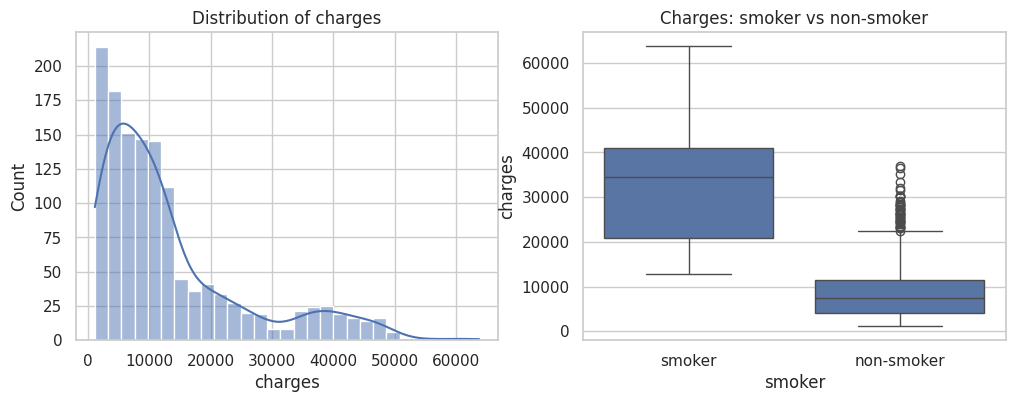

           mean   median  count
smoker                         
0        8441.0   7346.0   1063
1       32050.0  34456.0    274


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["charges"], kde=True, ax=ax[0]); ax[0].set_title("Distribution of charges")
sns.boxplot(x=df["smoker"].map({0: "non-smoker", 1: "smoker"}), y=df["charges"], ax=ax[1]); ax[1].set_title("Charges: smoker vs non-smoker")
plt.show()
print(df.groupby("smoker")["charges"].agg(["mean", "median", "count"]).round(0))

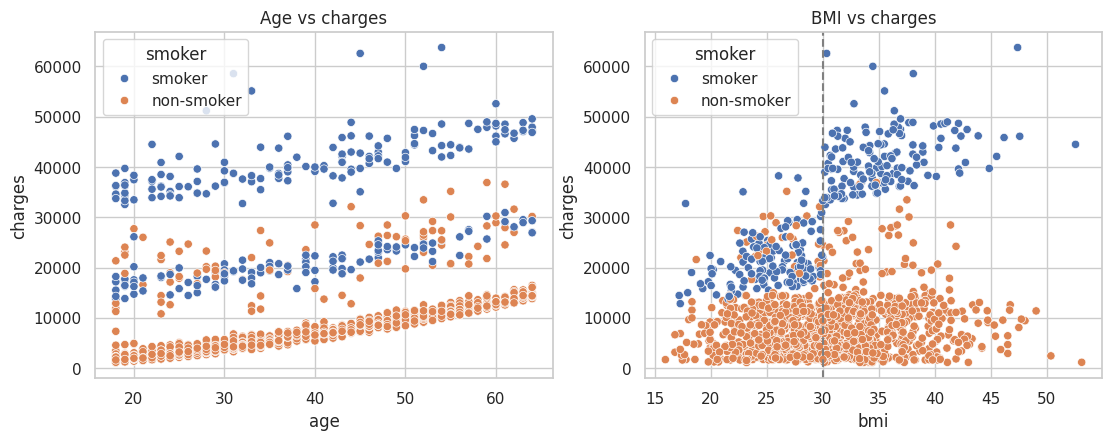

In [7]:
lab = df["smoker"].map({0: "non-smoker", 1: "smoker"})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x=df["age"], y=df["charges"], hue=lab, ax=ax[0]); ax[0].set_title("Age vs charges")
sns.scatterplot(x=df["bmi"], y=df["charges"], hue=lab, ax=ax[1]); ax[1].axvline(30, color="gray", ls="--"); ax[1].set_title("BMI vs charges")
plt.show()

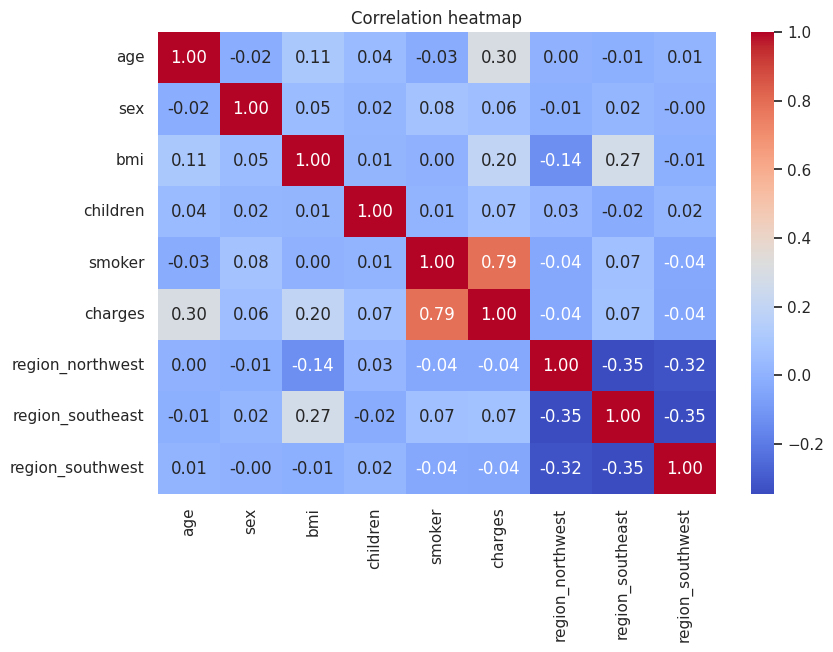

charges             1.000
smoker              0.787
age                 0.298
bmi                 0.198
region_southeast    0.074
children            0.067
sex                 0.058
region_northwest   -0.039
region_southwest   -0.044
Name: charges, dtype: float64

In [8]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()
df.corr()["charges"].sort_values(ascending=False).round(3)

In [9]:
q1, q3 = df["charges"].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
outliers = df[df["charges"] > upper]
print("Upper limit:", round(upper, 2), "| outliers:", len(outliers), "| smokers among them:", int(outliers["smoker"].sum()))

Upper limit: 34524.78 | outliers: 139 | smokers among them: 136


**Key EDA findings**
- Smokers pay about 4x more than non-smokers; smoking is the strongest feature (correlation 0.79).
- Age has a moderate positive effect (0.30); BMI is weak overall (0.20) but matters mainly for smokers.
- Sex, children and region have very little effect.
- Charges are right-skewed with 139 high-cost outliers (136 smokers), kept because they are real cases.

## 4. Train the model

In [10]:
X = df.drop("charges", axis=1)
y = df["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 2))
pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_.round(2)})

Train: (1069, 8) | Test: (268, 8)
Intercept: -11092.65


,Feature,Coefficient
0,age,248.21
1,sex,-101.54
2,bmi,318.70
3,children,533.01
4,smoker,23077.76
5,region_northwest,-391.76
6,region_southeast,-838.92
7,region_southwest,-659.14


## 5. Evaluate the model (test set)

In [11]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MAE : {mae:,.2f}\nMSE : {mse:,.2f}\nRMSE: {rmse:,.2f}\nR2  : {r2:.4f}")
print("Training R2:", round(model.score(X_train, y_train), 4))

MAE : 4,177.05
MSE : 35,478,020.68
RMSE: 5,956.34
R2  : 0.8069
Training R2: 0.7299


In [12]:
baseline = np.full(len(y_test), y_train.mean())
print("Baseline (predict the average) MAE:", round(mean_absolute_error(y_test, baseline), 2),
      "| R2:", round(r2_score(y_test, baseline), 3))

Baseline (predict the average) MAE: 9861.8 | R2: -0.008


,Actual,Predicted,Error
0,8688.86,8143.69,545.17
1,5708.87,5737.12,-28.25
2,11436.74,14369.31,-2932.57
3,38746.36,31745.51,7000.85
4,4463.21,8962.39,-4499.18
5,9304.70,13149.72,-3845.02
6,38511.63,30446.76,8064.87
7,2150.47,1453.29,697.18
8,7345.73,10633.02,-3287.29
9,10264.44,11318.94,-1054.50


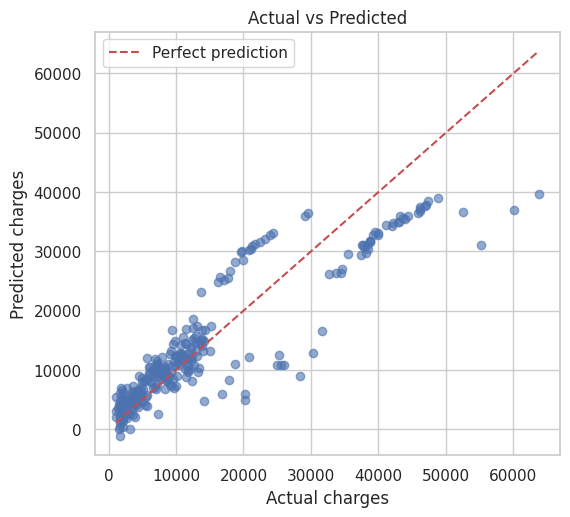

In [13]:
comparison = pd.DataFrame({"Actual": y_test.values[:10].round(2), "Predicted": y_pred[:10].round(2)})
comparison["Error"] = (comparison["Actual"] - comparison["Predicted"]).round(2)
display(comparison)

plt.figure(figsize=(6, 5.5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Perfect prediction")
plt.xlabel("Actual charges"); plt.ylabel("Predicted charges"); plt.title("Actual vs Predicted"); plt.legend(); plt.show()

## 6. Predict for new customers

In [14]:
def predict_cost(age, bmi, children, sex, smoker, region):
    row = pd.DataFrame([{
        "age": age, "sex": 1 if sex == "male" else 0, "bmi": bmi, "children": children,
        "smoker": 1 if smoker == "yes" else 0,
        "region_northwest": int(region == "northwest"),
        "region_southeast": int(region == "southeast"),
        "region_southwest": int(region == "southwest"),
    }])[X.columns]
    return max(model.predict(row)[0], 0)

for case in [(25, 22.0, 0, "male", "no", "northeast"),
             (45, 35.0, 2, "female", "yes", "southeast"),
             (60, 28.0, 1, "male", "yes", "northwest")]:
    print(case, "->", f"${predict_cost(*case):,.2f}")

(25, 22.0, 0, 'male', 'no', 'northeast') -> $2,022.51
(45, 35.0, 2, 'female', 'yes', 'southeast') -> $34,536.25
(60, 28.0, 1, 'male', 'yes', 'northwest') -> $35,841.10


## 7. Conclusion
The Multiple Linear Regression model explains about 81% of the variation in charges on unseen data (test R² 0.81, MAE about 4,177). It underestimates very high charges (mostly smokers with high BMI) because a simple linear model cannot capture the smoker x BMI interaction. Adding interaction features or trying tree-based models are the next steps.